### Import modules

In [4]:
!pip install kagglehub -q
!pip install tensorflow -q
!pip install opencv-python -q
!pip install scikit-image -q


import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tqdm import tqdm
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

from skimage.feature import hog, graycomatrix, graycoprops
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
import cv2
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from tqdm import tqdm



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.1.1 requires numpy<2.0,>=1.16; python_version <= "3.11", but you have numpy 2.4.6 which is incompatible.
matplotlib 3.8.0 requires numpy<2,>=1.21, but you have numpy 2.4.6 which is incompatible.
scikit-learn 1.3.1 requires numpy<2.0,>=1.17.3, but you have numpy 2.4.6 which is incompatible.
scipy 1.11.3 requires numpy<1.28.0,>=1.21.6, but you have numpy 2.4.6 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.


Download the dataset

In [ ]:

# Set download path
os.environ["KAGGLEHUB_CACHE"] = "dataset-backup"

# Download from kaggle 
# path = kagglehub.dataset_download("emmarex/plantdisease")    #Commented to prevent re-downloading 

# Followed my manually de-nesting the dataset 

### Preprocess images by resizing, normalising, and applying suitable augmentation

In [5]:
# Define dataset path 
DATASET_PATH = "dataset"

# Define image size 
IMAGE_SIZE = (224, 224)

# Define batch size 
BATCH_SIZE = 32

# Load the training raw dataset 
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    directory=DATASET_PATH,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True, # Shuffle images to prevent the models learning a pattern 
    validation_split=0.2,
    subset="training",
    seed=123
)

# Load the raw training dataset
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    directory=DATASET_PATH,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,  
    validation_split=0.2,
    subset="validation",
    seed=123
)

# Get class names and num of classes before we cache the data
class_names = raw_train_ds.class_names
num_classes = len(class_names)

# Cache raw data
raw_train_ds = raw_train_ds.cache("shared_train_cache")
raw_test_ds = raw_test_ds.cache("shared_test_cache")


# We are going to loop through all the raw data here to build the cache
# If we don't do this, the cache will be partially built only by the next cell
print("Building Cache.....")
for batch in tqdm(raw_train_ds):
    pass 

print("Building Testing Cache to SSD (Do not interrupt)...")
for batch in tqdm(raw_test_ds):
    pass 

print("Cache complete!")

# Print out all the classes
print("\nDiscovered", len(class_names), "classes:\n")
for i, j in enumerate(class_names):
    print(i + 1, "-", j)

# Aug and Normalisaiotn pipeline for classical ML models training data
train_augmentation_pipeline = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomBrightness(0.1),
])

cnn_augmentation_pipeline = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2), # Increased rotation
    tf.keras.layers.RandomZoom(0.2), # Zoom in/out by up to 20%
    tf.keras.layers.RandomContrast(0.2), # Randomly change lighting
    tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1) # Shift off-center
])

# Nomralise and Augment the dataset for classical ML models training data 
train_ds_ml = raw_train_ds.map(
    lambda x, y: (train_augmentation_pipeline(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(buffer_size=tf.data.AUTOTUNE)

# Augment training data for CNN model 
train_ds_cnn = raw_train_ds.map(
    lambda x, y: (cnn_augmentation_pipeline(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(buffer_size=tf.data.AUTOTUNE)

# CNN model testing data stream
test_ds_cnn = raw_test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

# ML model testing data stream 
test_ds_ml = raw_test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)



Found 20640 files belonging to 15 classes.
Using 16512 files for training.
Found 20640 files belonging to 15 classes.
Using 4128 files for validation.
Building Cache.....


100% 516/516 [00:22<00:00, 22.49it/s]W0000 00:00:1793451776.530130   69963 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
100% 516/516 [00:22<00:00, 23.11it/s]


Building Testing Cache to SSD (Do not interrupt)...


 97% 125/129 [00:03<00:00, 42.70it/s]W0000 00:00:1793451780.175449   69963 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
100% 129/129 [00:03<00:00, 35.67it/s]


Cache complete!

Discovered 15 classes:

1 - Pepper__bell___Bacterial_spot
2 - Pepper__bell___healthy
3 - Potato___Early_blight
4 - Potato___Late_blight
5 - Potato___healthy
6 - Tomato_Bacterial_spot
7 - Tomato_Early_blight
8 - Tomato_Late_blight
9 - Tomato_Leaf_Mold
10 - Tomato_Septoria_leaf_spot
11 - Tomato_Spider_mites_Two_spotted_spider_mite
12 - Tomato__Target_Spot
13 - Tomato__Tomato_YellowLeaf__Curl_Virus
14 - Tomato__Tomato_mosaic_virus
15 - Tomato_healthy


### Explore and visualise representative examples from different classes.

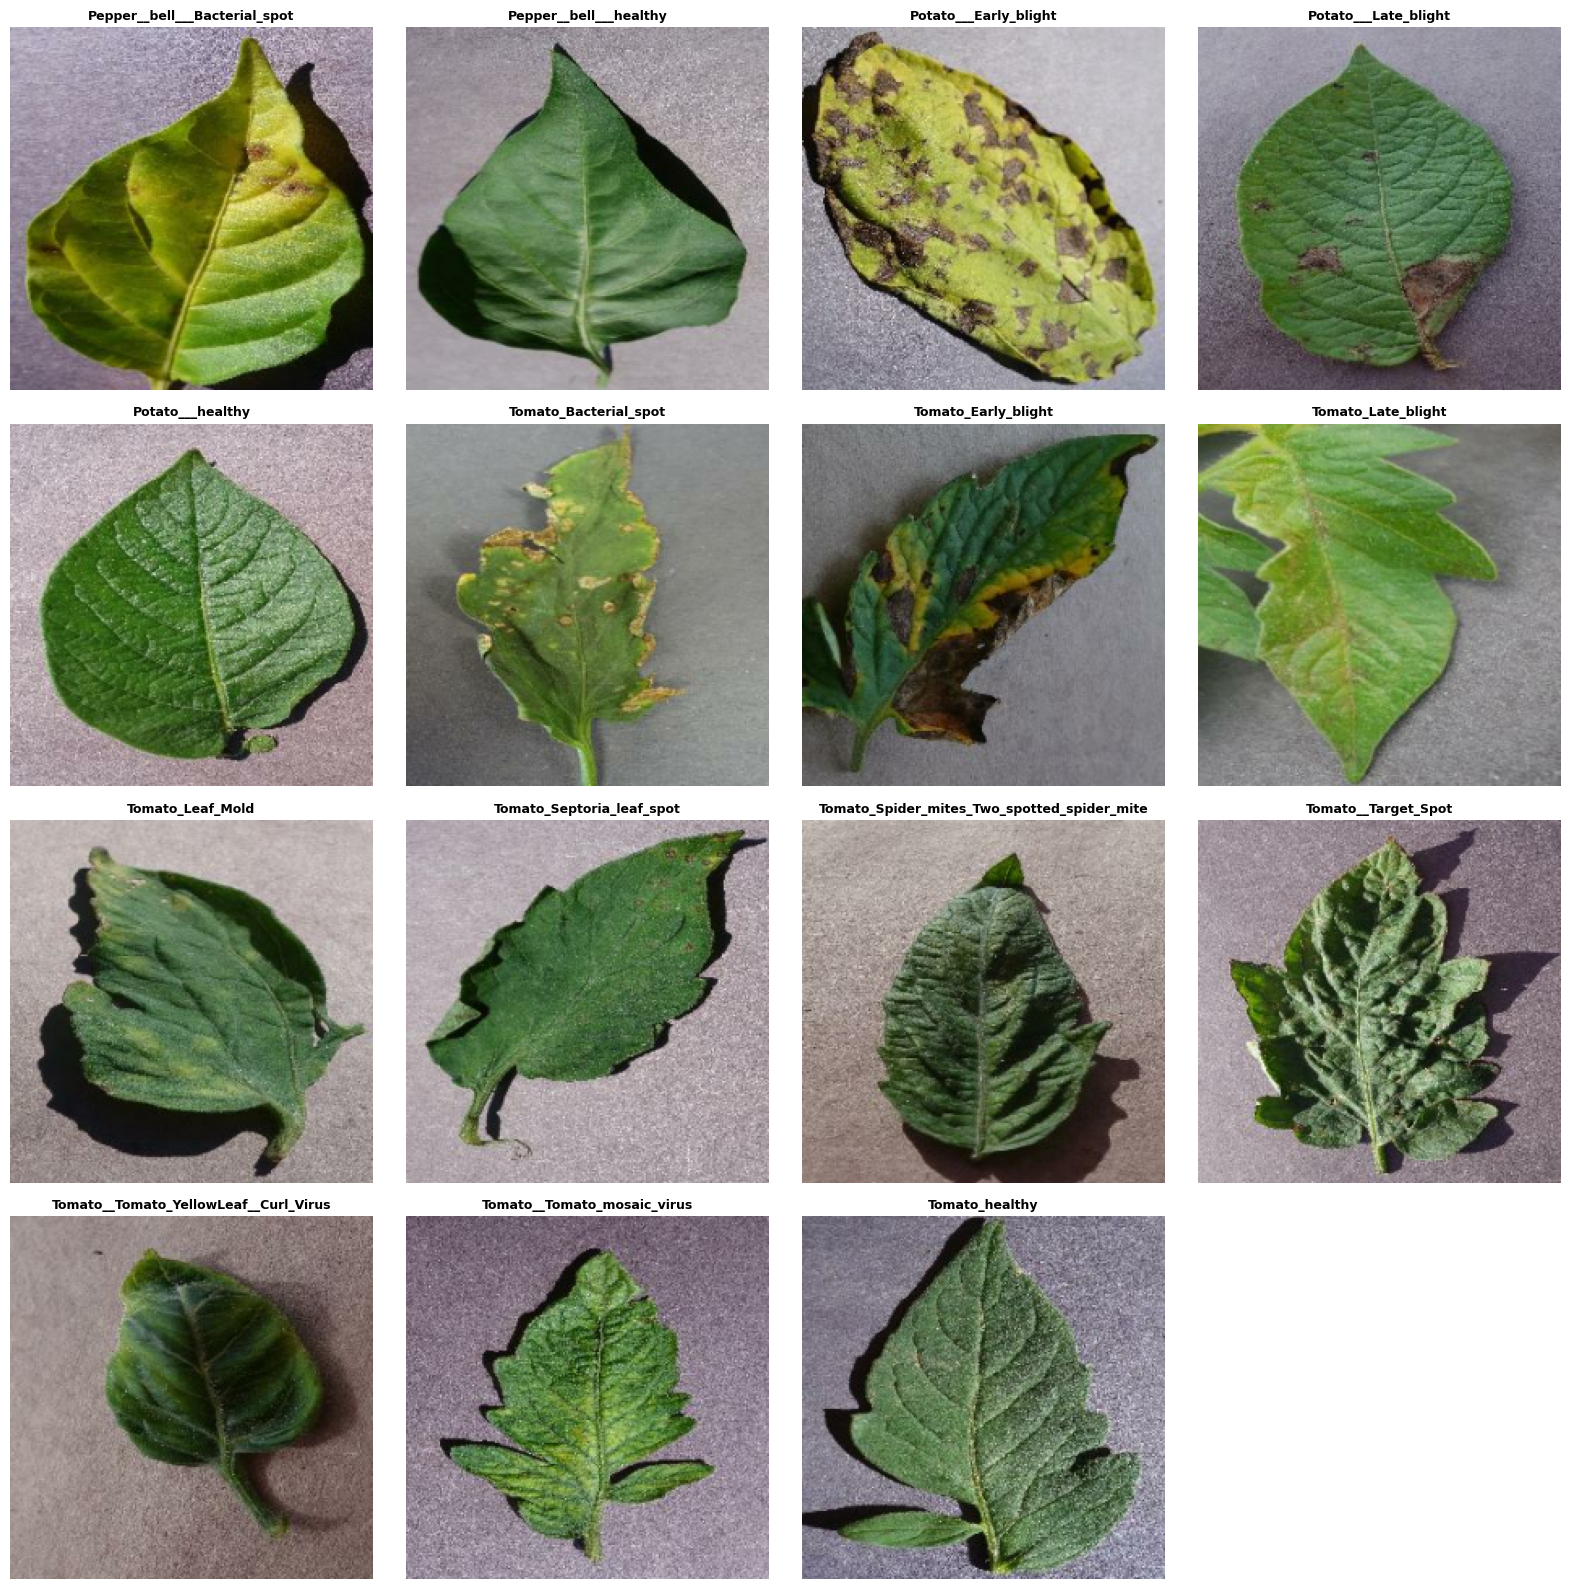

In [6]:
# init dictionary to store found classes 
found_classes = {}

# Loop through the raw training dataset
for images, labels in raw_train_ds.as_numpy_iterator():
    # Loop through (image, class) tuple in batch
    for img, lbl in zip(images, labels):
        # If the class hasn't been seen yet, add it too the dictionary 
        if lbl not in found_classes:
            found_classes[lbl] = img
        # If we've got an image from each class then stop 
        if len(found_classes) == num_classes:
            break
    # Same again for the outer loop 
    if len(found_classes) == num_classes:
        break

plt.figure(figsize=(16, 16))

# Loop through the found images 
for idx, (lbl_idx, img) in enumerate(sorted(found_classes.items())):
    plt.subplot(4, 4, idx + 1)

    img_display = img.astype("uint8")

    plt.imshow(img_display)
    plt.title(class_names[lbl_idx], fontsize=9, fontweight='bold')
    plt.axis("off")

plt.tight_layout()
plt.show()

### Extract suitable image features such as colour histograms, HOG, or texture features 

In [7]:
def extractFeatures(img):
    img = img.astype(np.uint8)
    
    # Convert to grayscale
    grayscale = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Gives the model a complete colour overview 
    RGB = np.concatenate(
        [cv2.calcHist([img], [i], None, [32], [0, 256]).flatten() for i in range(3)]
    )

    # Overivew of sharp edges/corners 
    hog_features = hog(
        grayscale, 
        orientations=8, 
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), 
        block_norm='L2-Hys', 
        visualize=False
    )

    # Contrast and smoothness 
    glcm = graycomatrix(
        grayscale // 8, 
        distances=[1, 3], 
        angles=[0, np.pi/4], 
        levels=32, 
        symmetric=True, 
        normed=True
    )
    
    texture_features = np.concatenate([
         graycoprops(glcm, 'contrast').flatten(), # Contrast
         graycoprops(glcm, 'correlation').flatten(), # Correlation
         graycoprops(glcm, 'energy').flatten(), # Energy
         graycoprops(glcm, 'homogeneity').flatten() # Homegenity 
    ])
    
    return np.concatenate([
        RGB, 
        hog_features, 
        texture_features
    ])


def process_dataset(dataset, n_jobs=4):
    X_list = []
    y_list = []
    
    for images, labels in tqdm(dataset, desc="Processing Batches"):        
        batch_features = Parallel(n_jobs=n_jobs)(
            delayed(extractFeatures)(img) 
            for img in images.numpy()
        )
        
        X_list.extend(batch_features)
        y_list.extend(labels.numpy())
        
    return np.array(X_list), np.array(y_list)


X_train, y_train = process_dataset(train_ds_ml, n_jobs=4)
X_test, y_test = process_dataset(test_ds_ml, n_jobs=4)

print(f"\nFinal Training Feature Matrix Shape: {X_train.shape}")
print(f"Final Testing Feature Matrix Shape: {X_test.shape}")

Processing Batches: 100% 516/516 [00:35<00:00, 14.60it/s]
Processing Batches: 100% 129/129 [00:07<00:00, 16.47it/s]



Final Training Feature Matrix Shape: (16512, 5520)
Final Testing Feature Matrix Shape: (4128, 5520)


### Scale the data

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit on training data and transform it
X_test_scaled = scaler.transform(X_test) # Only transform the test data using the parameters learned from the training data


### Train and compare Classiscal ML models

In [9]:
# Setup our models

models = {
    # LogisticRegression with 10000 iterations, allows time for the data to converge but allow it to stop if imporvments aren't seen 
    # SGDClassifier rather than Standard LogisitcRegression as it is better/faster with images
    'Logistic Regression': SGDClassifier(loss='log_loss', max_iter=10000, early_stopping=True, random_state=42, n_jobs=-1),
    # Use SGDClassifier with loss set too 'hinge' for an SVM model capable of multi-threading 
    'Linear SVM': SGDClassifier(loss='hinge', max_iter=10000, early_stopping=True, random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    
    # Decision Tree Classifier with a max depth of 10 to prevent over-fitting
    'Decision Tree': DecisionTreeClassifier(max_depth=20, random_state=42),

    # Random Forest with 100 trees, more has show to not have much of an effect on accuracy
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42)
}

# Init results list
results = []

# Start the lopp through the models
for name, model in models.items():
    print("Training: ", name, "\n", flush=True)

    # Logistic regression, Decsion Tree and Gradient Boositng don't need scaled data
    if name in ('Decision Tree', 'Random Forest', 'Gradient Boosting'):
        X_train_data = X_train
        X_test_data = X_test
    else:
        X_train_data = X_train_scaled
        X_test_data = X_test_scaled
        
    start = time.time() # Start timer 
    
    model.fit(X_train_data, y_train) # Fit data to model 
    
    trainingTime = time.time() - start # Caclulate training time 
    mins, secs = divmod(int(trainingTime), 60) # Convert to mins and seconds
    print(f"{name}: Training complete in {mins}m {secs}s")
    
    y_pred = model.predict(X_test_data) # Test model 
    
    # Generate Precision, Recall and F1-score data
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    
    # Save to the results 
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred), # The % of correct predictions 
        'Precision (Macro)': prec, # True Positives / True Positves + False Positives 
        'Recall (Macro)': rec, # True Positves / True Positives + False Negatives 
        'F1-Score (Macro)': f1, # 2 * ((Precision * Recall) / (Precision + Recall)) - Harmonic Mean
        'Training Time': f"{mins}m {secs}s" # Training time formatted 
    })

# Format the results into a table, sort by Accuracy
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print("============================== Classical ML Model Comparison ==============================\n")
print(results_df.to_string(index=False))

Training:  Logistic Regression 

Logistic Regression: Training complete in 0m 1s
Training:  Linear SVM 

Linear SVM: Training complete in 0m 1s
Training:  K-Nearest Neighbors 



Exception ignored on calling ctypes callback function: <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0xfffea1b90cc0>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/threadpoolctl.py", line 847, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/opt/conda/lib/python3.11/site-packages/threadpoolctl.py", line 984, in _make_controller_from_path
    lib_controller = controller_class(filepath=filepath, prefix=prefix)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.11/site-packages/threadpoolctl.py", line 111, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.11/ctypes/__init__.py", line 376, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
OSError: dlopen()

K-Nearest Neighbors: Training complete in 0m 0s
Training:  Decision Tree 

Decision Tree: Training complete in 1m 30s
Training:  Random Forest 

Random Forest: Training complete in 0m 6s
Training:  Gradient Boosting 

Gradient Boosting: Training complete in 2m 11s
============================== Classical ML Model Comparison ==============================

              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro) Training Time
  Gradient Boosting  0.610465           0.646422        0.529628          0.547130        2m 11s
Logistic Regression  0.579215           0.550720        0.523460          0.512758         0m 1s
         Linear SVM  0.577519           0.566073        0.521100          0.514767         0m 1s
      Random Forest  0.534884           0.651939        0.432406          0.430991         0m 6s
      Decision Tree  0.343023           0.289209        0.274067          0.263156        1m 30s
K-Nearest Neighbors  0.255572           0.372455        0.21

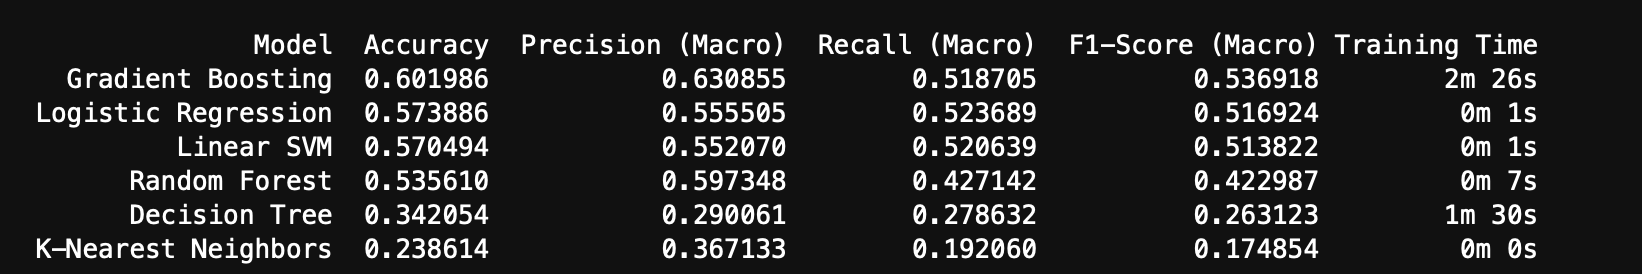



In [10]:
model = EfficientNetB0(
    include_top=False, # Drop current output layer 
    weights='imagenet', # Load the imagenet weights 
    input_shape=(224, 224, 3) # 224x244 + RGB
)
model.trainable = False  # Freeze weights 

inputs = layers.Input(shape=(224, 224, 3)) # Create entry node 
x = preprocess_input(inputs)  # Scale/Normalise the data for EfficientNetB0
x = model(x, training=False)  # Pass the data to the model 
x = layers.GlobalAveragePooling2D()(x) # Flatten to 1d vector 
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x) # Randomly drop 40% to prevent over-fitting, forces the model to learn
outputs = layers.Dense(num_classes, activation='softmax')(x) # Convert vector to probability score 

 # and finally package the pipeline 
full_model = tf.keras.Model(inputs, outputs, name="EfficientNetB0_Transfer")
cnn_start = time.time() # Start timer 

# Compile the model 
full_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), # Set the learning rate 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("======== Fit Model ======== ") 
fit_model = full_model.fit( # Fit the model
    train_ds_cnn, # Training data 
    validation_data=test_ds_cnn, # Validate against test data 
    epochs=10
)

model.trainable = True # Unfreeze weights 

# Then freeze all but the top 50 layers 
for layer in model.layers[:-50]:
    layer.trainable = False

for layer in model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate, prevent massive changes to weights 
full_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # Set learning rate 
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Define the callbacks 
callbacks = [
    # Stop early if the val_lost doesn't improve for 4 epochs 
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),

    # Reduce the learning rate to 20% if if val_lost plateus 
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2)
]

print("\n--- Fine Tune the model ---")
fine_tune_model = full_model.fit(
    train_ds_cnn, # training data 
    validation_data=test_ds_cnn, # testing data 
    epochs=15,
    callbacks=callbacks # Load the callback functions 
)
# End the timer and format into mins/secs
cnn_total_time = time.time() - cnn_start 
cnn_mins, cnn_secs = divmod(int(cnn_total_time), 60)




======== Fit Model ======== 
Epoch 1/10


/opt/conda/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


516/516 ━━━━━━━━━━━━━━━━━━━━ 92s 171ms/step - accuracy: 0.7535 - loss: 0.7713 - val_accuracy: 0.8215 - val_loss: 0.5153
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 91s 175ms/step - accuracy: 0.8583 - loss: 0.4238 - val_accuracy: 0.8798 - val_loss: 0.3610
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 92s 176ms/step - accuracy: 0.8812 - loss: 0.3494 - val_accuracy: 0.8813 - val_loss: 0.3444
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 94s 180ms/step - accuracy: 0.8906 - loss: 0.3193 - val_accuracy: 0.8878 - val_loss: 0.3110
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 106s 204ms/step - accuracy: 0.9030 - loss: 0.2857 - val_accuracy: 0.9029 - val_loss: 0.2858
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 113s 218ms/step - accuracy: 0.9070 - loss: 0.2763 - val_accuracy: 0.9167 - val_loss: 0.2513
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 119s 230ms/step - accuracy: 0.9118 - loss: 0.2536 - val_accuracy: 0.9026 - val_loss: 0.2772
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 114s 220ms/step - accuracy: 0.9130 - loss: 0.2492 -

### Compare CNN to classical ML models 

In [11]:
y_pred_probs = full_model.predict(test_ds_cnn)
y_pred = np.argmax(y_pred_probs, axis=1)

y_true = np.concatenate([y for x, y in test_ds_cnn])

# 2. Get metrics from predictions 
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
acc = accuracy_score(y_true, y_pred)

# 3. Add Metrics to results dictionary 
cnn_results = {
    'Model': 'EfficientNetB0 (Fine-Tuned)',
    'Accuracy': acc,
    'Precision (Macro)': prec,
    'Recall (Macro)': rec,
    'F1-Score (Macro)': f1,
    'Training Time': f"{cnn_mins}m {cnn_secs}s"
}

# 4. Append CNN results to classical ML model results 
results_df = pd.concat([results_df, pd.DataFrame([cnn_results])], ignore_index=True)
results_df = results_df.sort_values(by='Accuracy', ascending=False)

print("\n========================== Final All-Model Comparison ==========================\n")
print(results_df.to_string(index=False))

# 5. Save the trained model
full_model.save("efficientnet_final.keras")
print("\nModel saved successfully as 'efficientnet_final.keras'")


129/129 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step

========================== Final All-Model Comparison ==========================

                      Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro) Training Time
EfficientNetB0 (Fine-Tuned)  0.959060           0.963415        0.956394          0.958522       49m 19s
          Gradient Boosting  0.610465           0.646422        0.529628          0.547130        2m 11s
        Logistic Regression  0.579215           0.550720        0.523460          0.512758         0m 1s
                 Linear SVM  0.577519           0.566073        0.521100          0.514767         0m 1s
              Random Forest  0.534884           0.651939        0.432406          0.430991         0m 6s
              Decision Tree  0.343023           0.289209        0.274067          0.263156        1m 30s
        K-Nearest Neighbors  0.255572           0.372455        0.210895          0.193745         0m 0s

Model saved successfully as 'effic

| Model | Accuracy | Precision (Macro) | Recall (Macro) | F1-Score (Macro) | Training Time |
| --- | --- | --- | --- | --- | --- |
| **EfficientNetB0 (Fine-Tuned)** | **0.959060** | **0.963415** | **0.956394** | **0.958522** | **49m 19s** |
| Gradient Boosting | 0.610465 | 0.646422 | 0.529628 | 0.547130 | 2m 11s |
| Logistic Regression | 0.579215 | 0.550720 | 0.523460 | 0.512758 | 0m 1s |
| Linear SVM | 0.577519 | 0.566073 | 0.521100 | 0.514767 | 0m 1s |
| Random Forest | 0.534884 | 0.651939 | 0.432406 | 0.430991 | 0m 6s |
| Decision Tree | 0.343023 | 0.289209 | 0.274067 | 0.263156 | 1m 30s |
| K-Nearest Neighbors | 0.255572 | 0.372455 | 0.210895 | 0.193745 | 0m 0s |

### Plot learning curves

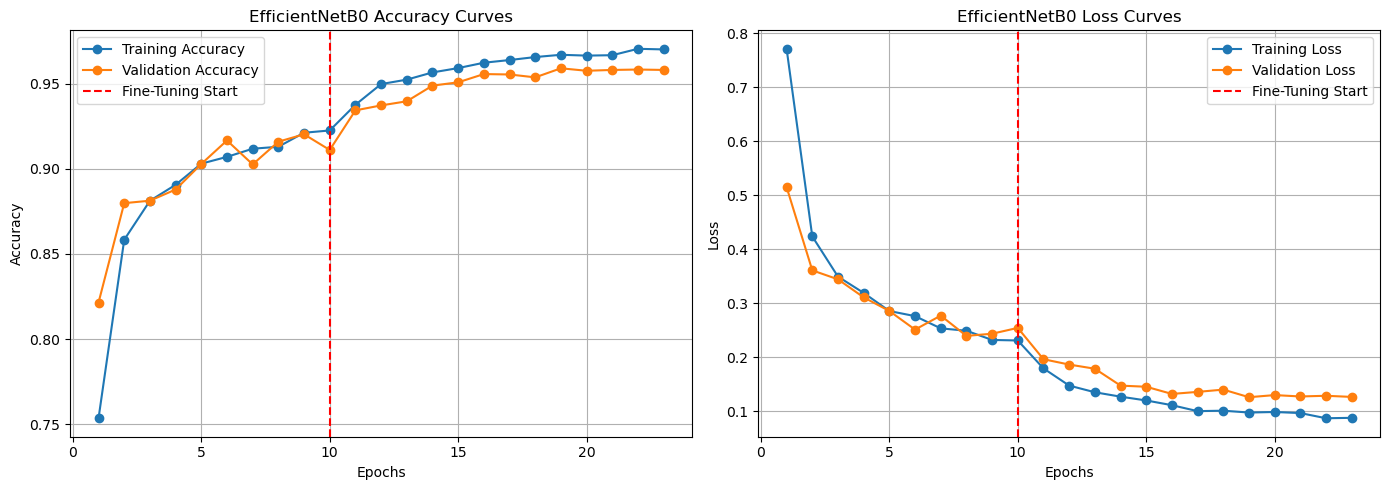

In [17]:

acc = fit_model.history['accuracy'] + fine_tune_model.history['accuracy']
val_acc = fit_model.history['val_accuracy'] + fine_tune_model.history['val_accuracy']

loss = fit_model.history['loss'] + fine_tune_model.history['loss']
val_loss = fit_model.history['val_loss'] + fine_tune_model.history['val_loss']

epochs_range = range(1, len(acc) + 1)
phase1_end = len(fit_model.history['accuracy'])

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.axvline(x=phase1_end, color='red', linestyle='--', label='Fine-Tuning Start')
plt.title('EfficientNetB0 Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.axvline(x=phase1_end, color='red', linestyle='--', label='Fine-Tuning Start')
plt.title('EfficientNetB0 Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Confusion Matrix

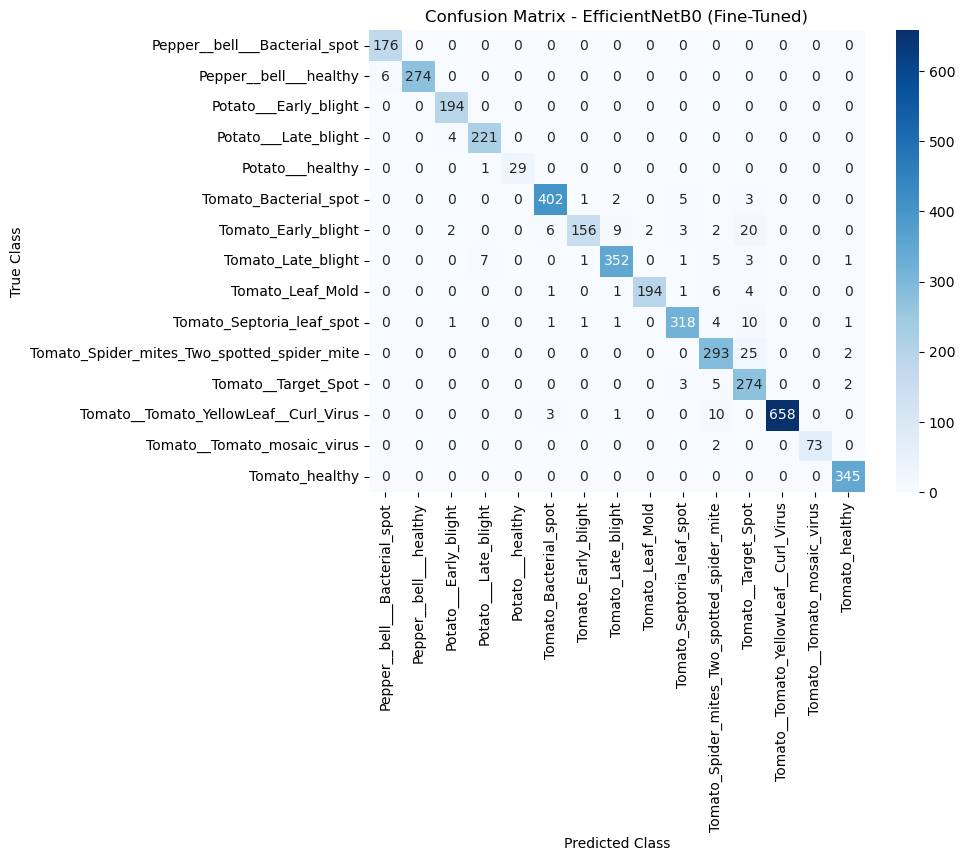

In [13]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=class_names if 'class_names' in locals() else 'auto',
    yticklabels=class_names if 'class_names' in locals() else 'auto'
)
plt.title('Confusion Matrix - EfficientNetB0 (Fine-Tuned)')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.show()

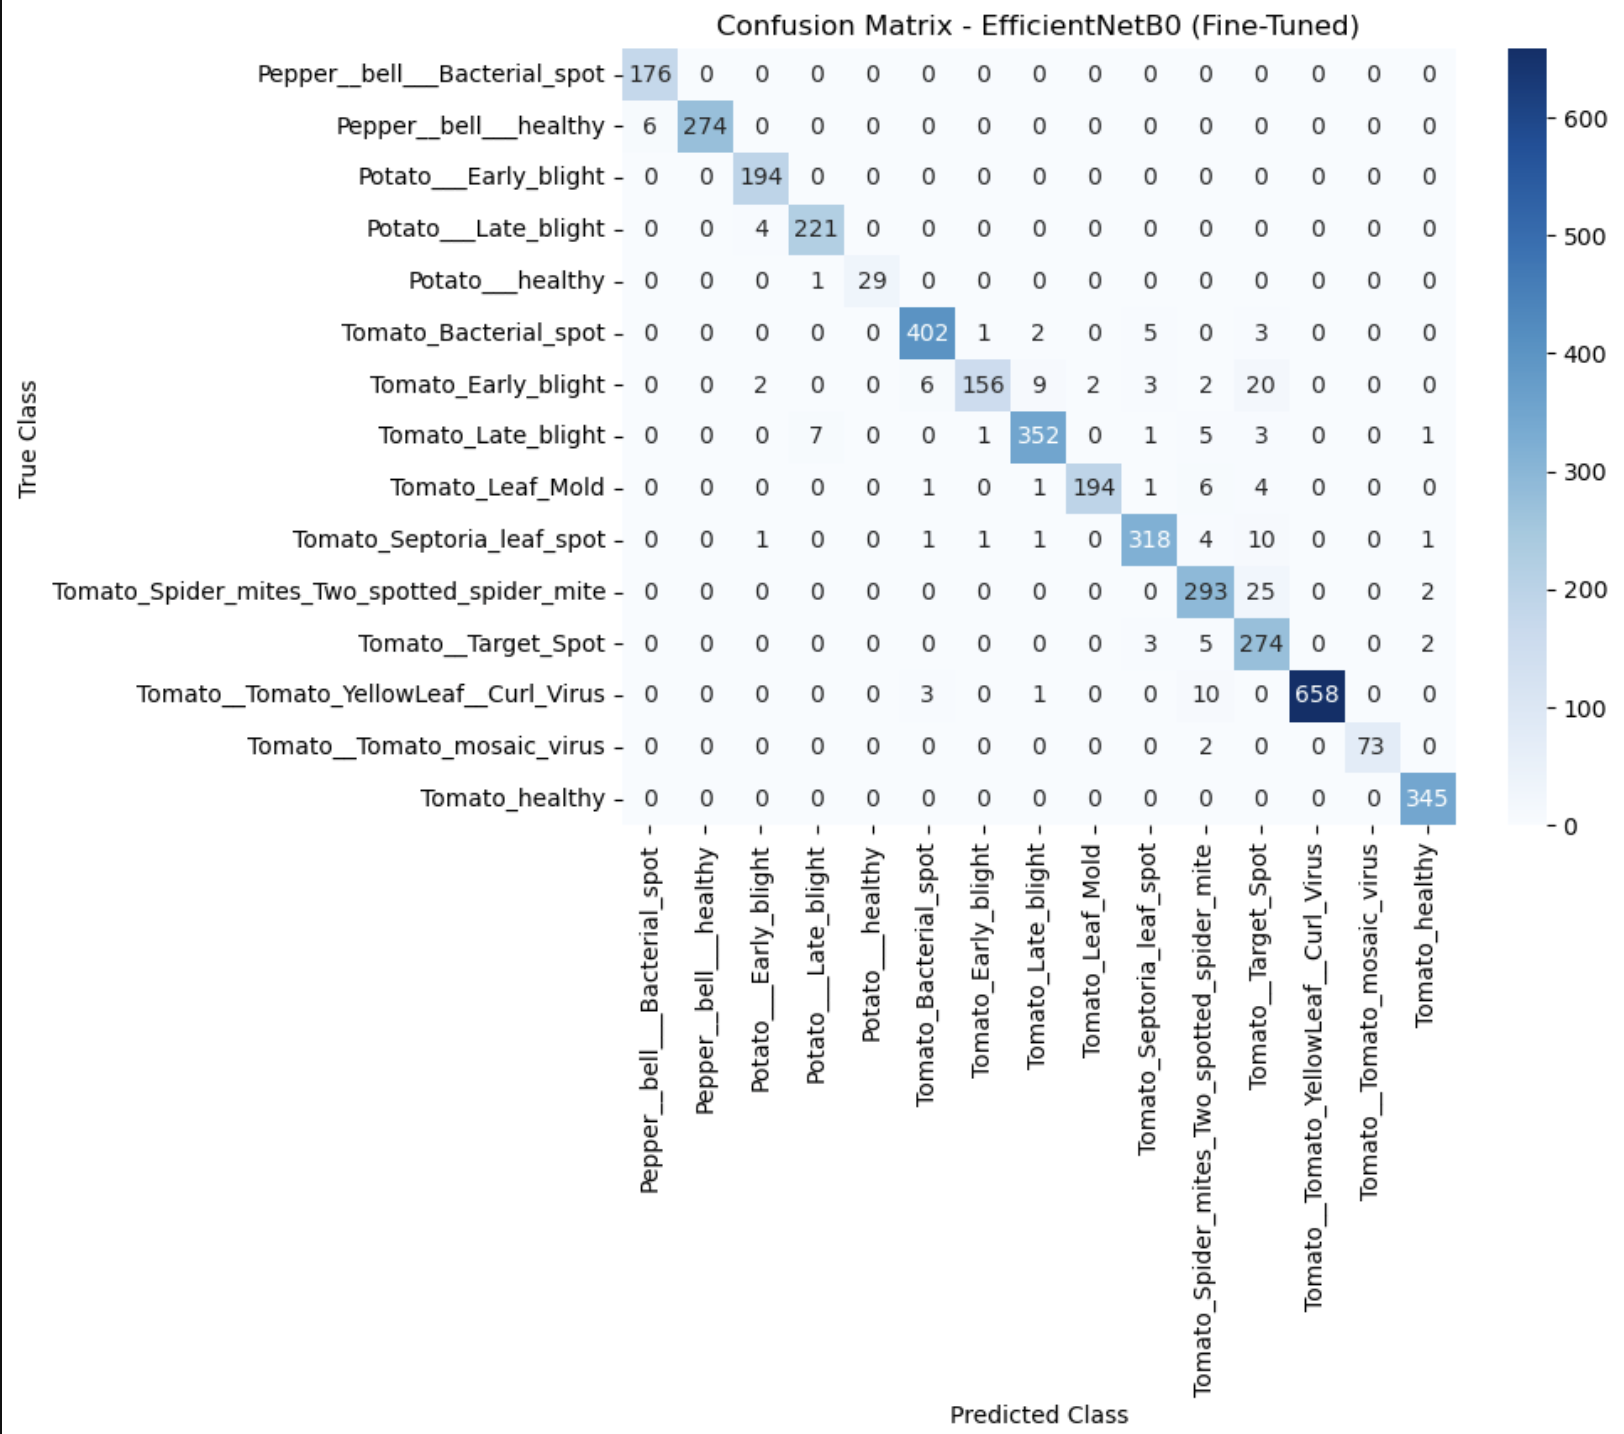

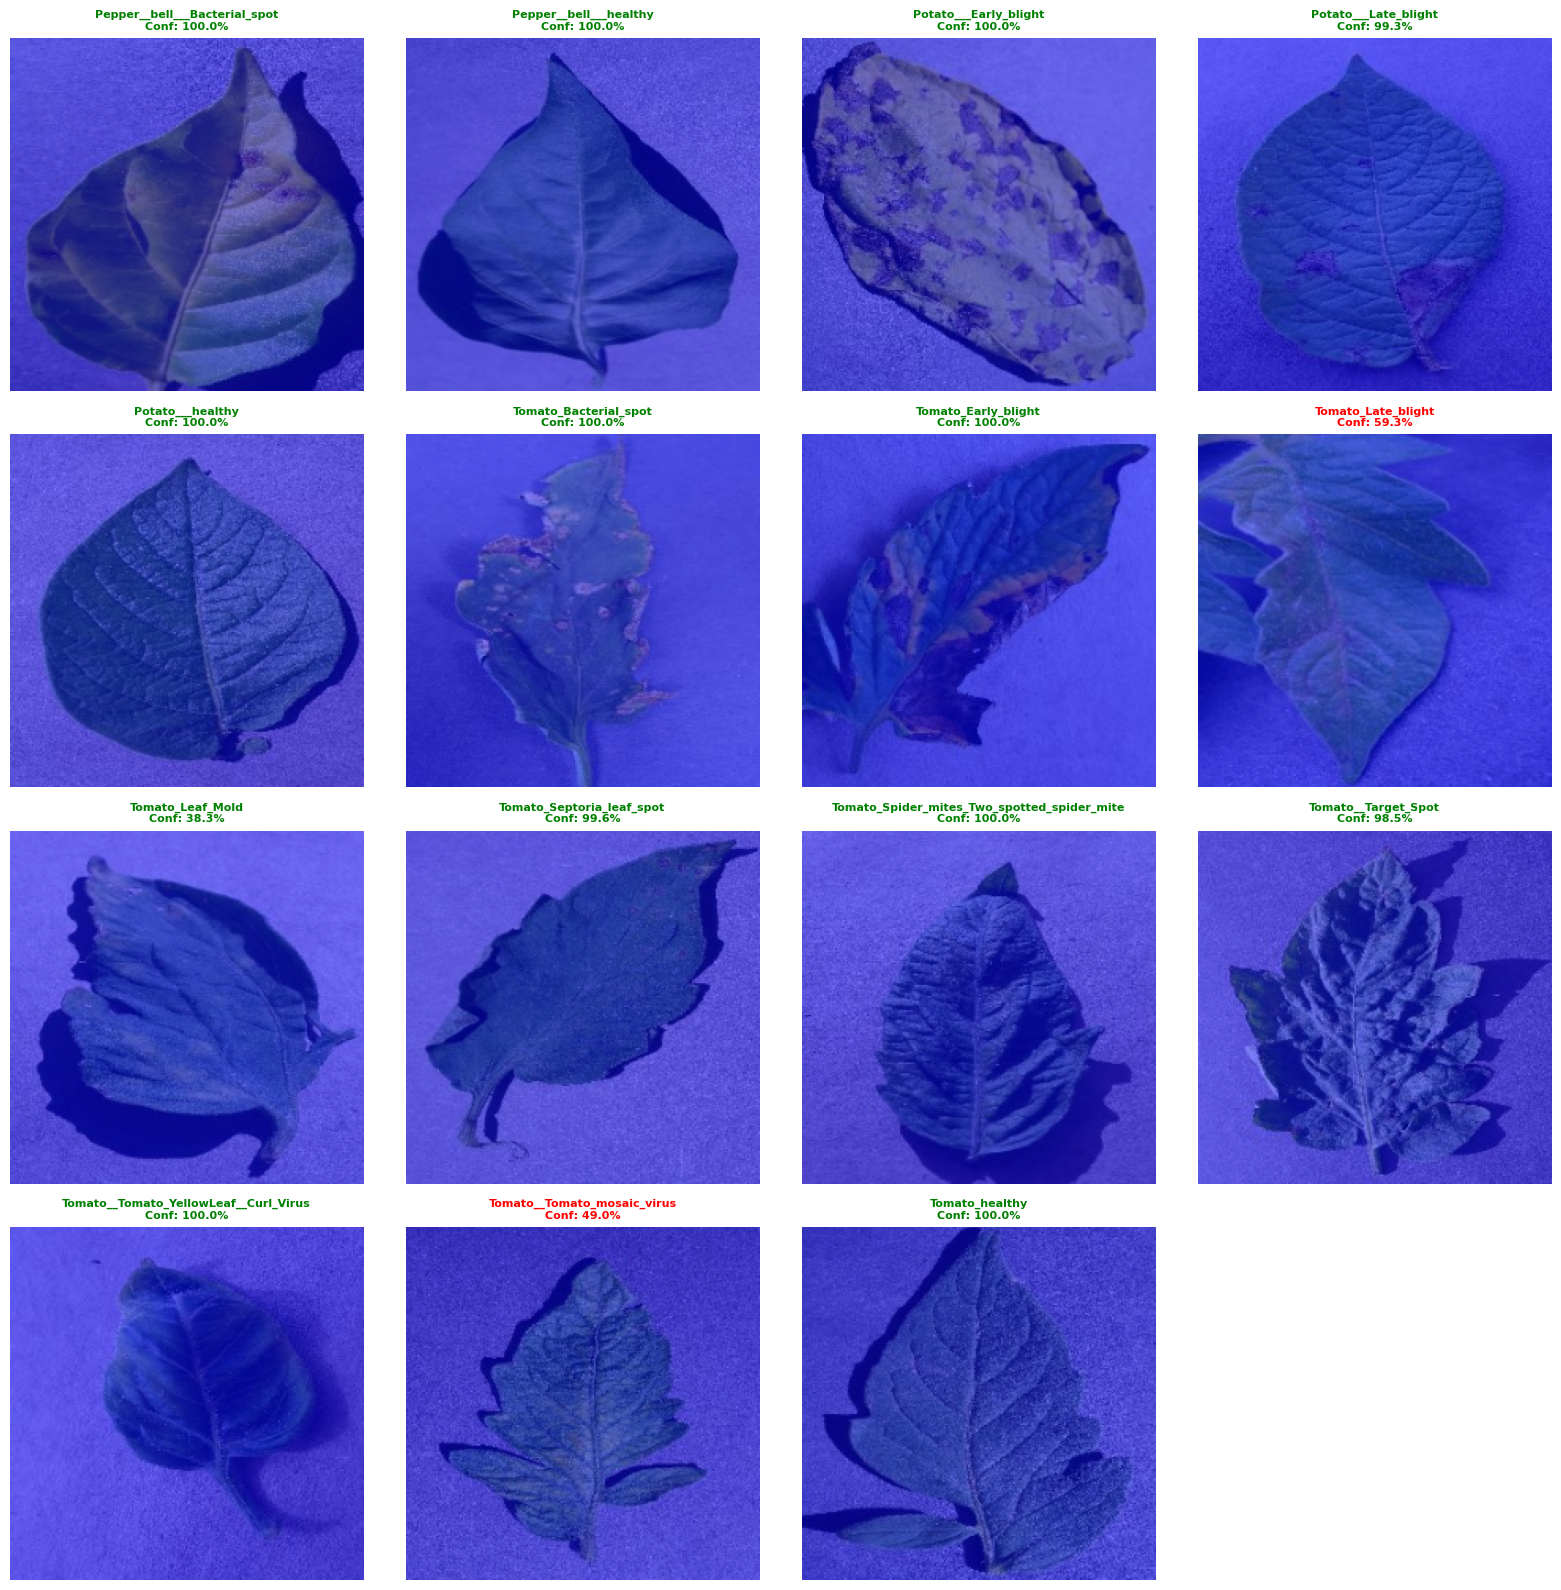